# Imports

In [1]:
#!pip install numpy pandas matplotlib seaborn scikit-learn xgboost lightgbm joblib



In [2]:
# ==============================
# Core libraries
# ==============================
import numpy as np
import pandas as pd

# ==============================
# Visualization (optionnel)
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# Preprocessing & pipeline
# ==============================
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# ==============================
# Models
# ==============================
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# ==============================
# Evaluation metrics
# ==============================
from sklearn.metrics import mean_squared_error, r2_score

# ==============================
# Utilities
# ==============================
import joblib
import warnings
warnings.filterwarnings('ignore')


## Description dataset :

In [3]:
df = pd.read_csv("C:\\Users\\Pc\\Documents\\stuff\\kraya\\4eme\\machine learning\\prix immobiliers\\machine-learning\\data\\sample_submission.csv")
test = pd.read_csv("C:\\Users\\Pc\\Documents\\stuff\\kraya\\4eme\\machine learning\\prix immobiliers\\machine-learning\\data\\test.csv")
train = pd.read_csv("C:\\Users\\Pc\\Documents\\stuff\\kraya\\4eme\\machine learning\\prix immobiliers\\machine-learning\\data\\train.csv")


train.csv – l’ensemble d’entraînement

test.csv – l’ensemble de test

data_description.txt – description complète de chaque colonne, initialement préparée par Dean De Cock puis légèrement modifiée pour correspondre aux noms de colonnes utilisés ici

sample_submission.csv – une soumission de référence issue d’une régression linéaire utilisant l’année et le mois de vente, la surface du terrain et le nombre de chambres



In [4]:
df


,Id,SalePrice
0,1461,169277.052498
1,1462,187758.393989
2,1463,183583.683570
3,1464,179317.477511
4,1465,150730.079977
...,...,...
1454,2915,167081.220949
1455,2916,164788.778231
1456,2917,219222.423400
1457,2918,184924.279659


In [5]:
test

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,2915,160,RM,21.0,1936,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2006,WD,Normal
1455,2916,160,RM,21.0,1894,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2006,WD,Abnorml
1456,2917,20,RL,160.0,20000,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2006,WD,Abnorml
1457,2918,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal


In [6]:
train

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


## Champs de données

- **SalePrice** : prix de vente du bien immobilier en dollars. C’est la variable cible que vous essayez de prédire.
- **MSSubClass** : classe du bâtiment
- **MSZoning** : classification générale du zonage
- **LotFrontage** : longueur en pieds de la façade du terrain donnant sur la rue
- **LotArea** : superficie du terrain en pieds carrés
- **Street** : type d’accès routier
- **Alley** : type d’accès par une allée
- **LotShape** : forme générale du terrain
- **LandContour** : planéité du terrain
- **Utilities** : type de services publics disponibles
- **LotConfig** : configuration du terrain
- **LandSlope** : pente du terrain
- **Neighborhood** : emplacements physiques dans les limites de la ville d’Ames
- **Condition1** : proximité d’une route principale ou d’une voie ferrée
- **Condition2** : proximité d’une route principale ou d’une voie ferrée (s’il y en a une seconde)
- **BldgType** : type d’habitation
- **HouseStyle** : style de l’habitation
- **OverallQual** : qualité globale des matériaux et des finitions
- **OverallCond** : évaluation de l’état général
- **YearBuilt** : année de construction initiale
- **YearRemodAdd** : année de rénovation
- **RoofStyle** : type de toiture
- **RoofMatl** : matériau de la toiture
- **Exterior1st** : revêtement extérieur de la maison
- **Exterior2nd** : revêtement extérieur de la maison (s’il y a plus d’un matériau)
- **MasVnrType** : type de parement en maçonnerie
- **MasVnrArea** : surface du parement en maçonnerie en pieds carrés
- **ExterQual** : qualité des matériaux extérieurs
- **ExterCond** : état actuel des matériaux extérieurs
- **Foundation** : type de fondation
- **BsmtQual** : hauteur / qualité du sous-sol
- **BsmtCond** : état général du sous-sol
- **BsmtExposure** : murs du sous-sol avec sortie ou au niveau du jardin
- **BsmtFinType1** : qualité de la première zone aménagée du sous-sol
- **BsmtFinSF1** : superficie aménagée du sous-sol de type 1 en pieds carrés
- **BsmtFinType2** : qualité de la seconde zone aménagée du sous-sol (si présente)
- **BsmtFinSF2** : superficie aménagée du sous-sol de type 2 en pieds carrés
- **BsmtUnfSF** : superficie non aménagée du sous-sol en pieds carrés
- **TotalBsmtSF** : superficie totale du sous-sol en pieds carrés
- **Heating** : type de chauffage
- **HeatingQC** : qualité et état du chauffage
- **CentralAir** : climatisation centrale
- **Electrical** : système électrique
- **1stFlrSF** : superficie du premier étage en pieds carrés
- **2ndFlrSF** : superficie du deuxième étage en pieds carrés
- **LowQualFinSF** : superficie aménagée de faible qualité (tous étages)
- **GrLivArea** : surface habitable hors sous-sol (au-dessus du sol) en pieds carrés
- **BsmtFullBath** : nombre de salles de bain complètes au sous-sol
- **BsmtHalfBath** : nombre de demi-salles de bain au sous-sol
- **FullBath** : nombre de salles de bain complètes au-dessus du sol
- **HalfBath** : nombre de demi-salles de bain au-dessus du sol
- **Bedroom** : nombre de chambres au-dessus du niveau du sous-sol
- **Kitchen** : nombre de cuisines
- **KitchenQual** : qualité de la cuisine
- **TotRmsAbvGrd** : nombre total de pièces au-dessus du sol (hors salles de bain)
- **Functional** : évaluation de la fonctionnalité de la maison
- **Fireplaces** : nombre de cheminées
- **FireplaceQu** : qualité de la cheminée
- **GarageType** : emplacement du garage
- **GarageYrBlt** : année de construction du garage
- **GarageFinish** : finition intérieure du garage
- **GarageCars** : capacité du garage en nombre de voitures
- **GarageArea** : superficie du garage en pieds carrés
- **GarageQual** : qualité du garage
- **GarageCond** : état du garage
- **PavedDrive** : allée pavée
- **WoodDeckSF** : surface de la terrasse en bois en pieds carrés
- **OpenPorchSF** : surface du porche ouvert en pieds carrés
- **EnclosedPorch** : surface du porche fermé en pieds carrés
- **3SsnPorch** : surface du porche trois saisons en pieds carrés
- **ScreenPorch** : surface du porche avec moustiquaire en pieds carrés
- **PoolArea** : surface de la piscine en pieds carrés
- **PoolQC** : qualité de la piscine
- **Fence** : qualité de la clôture
- **MiscFeature** : équipement ou caractéristique diverse non couverte ailleurs
- **MiscVal** : valeur en dollars de la caractéristique diverse
- **MoSold** : mois de vente
- **YrSold** : année de vente
- **SaleType** : type de vente
- **SaleCondition** : condition de la vente


# Description du dataset

## 1) Nombre d'instance (lignes):

In [7]:
df.shape[0]

1459

In [8]:
train.shape[0]

1460

In [9]:
test.shape[0]

1459

## 2) Nombres d'attribus (colonnes) :

In [10]:
df.shape[1]

2

In [11]:
train.shape[1]

81

In [12]:
test.shape[1]

80

Nombres lignes + colonnes

In [13]:
df.shape

(1459, 2)

In [14]:
train.shape

(1460, 81)

In [15]:
test.shape

(1459, 80)

## 3) Types de variables

In [16]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [17]:
train.dtypes.value_counts()


object     43
int64      35
float64     3
Name: count, dtype: int64

## Conclusion :
Le jeu de données est majoritairement composé de variables catégorielles  (43), avec 35 variables numériques entières et très peu de variables continues (3).
Cela implique un prétraitement des variables catégorielles (encodage) et une attention particulière à la mise à l’échelle des variables numériques avant l’entraînement du modèle.



In [18]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   object 
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   object 
 6   Alley          107 non-null    object 
 7   LotShape       1459 non-null   object 
 8   LandContour    1459 non-null   object 
 9   Utilities      1457 non-null   object 
 10  LotConfig      1459 non-null   object 
 11  LandSlope      1459 non-null   object 
 12  Neighborhood   1459 non-null   object 
 13  Condition1     1459 non-null   object 
 14  Condition2     1459 non-null   object 
 15  BldgType       1459 non-null   object 
 16  HouseStyle     1459 non-null   object 
 17  OverallQual    1459 non-null   int64  
 18  OverallC

In [19]:
test.dtypes.value_counts()

object     43
int64      26
float64    11
Name: count, dtype: int64

## 4) Variable cible :

 voir les collumns du test et du train

In [20]:
test.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [21]:
train.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

Comparaison entre train et test

In [22]:
train.columns.difference(test.columns)


Index(['SalePrice'], dtype='object')

## Conclusion :
- SalePrice est présente uniquement dans le dataset d’entraînement (absente du dataset de test)
- notre variable cible est SalePrice

In [23]:
train["SalePrice"].dtype


dtype('int64')

## Conclusion :
Cela indique un problème de régression car notre cible est de type entier

Analyser la signification métier

In [24]:

train["SalePrice"].head()

0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

## 5) Distribution des données :

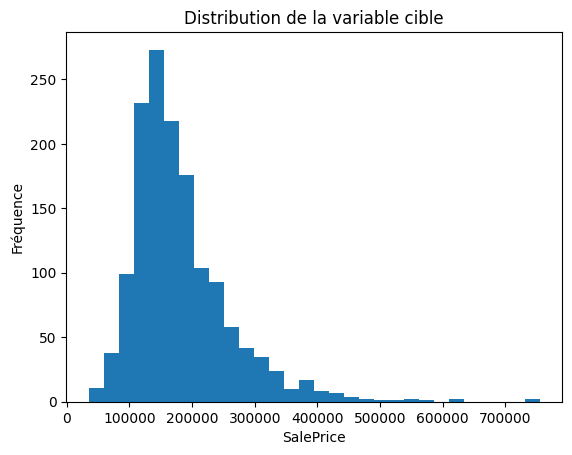

In [25]:


plt.hist(train["SalePrice"], bins=30)
plt.xlabel("SalePrice")
plt.ylabel("Fréquence")
plt.title("Distribution de la variable cible")
plt.show()


## Conclusion :
La distribution des prix de vente est asymétrique à droite, avec une majorité de propriétés vendues autour de 100 000 à 200 000 dollars.
Il y a quelques valeurs élevées (prix très hauts), mais elles sont rares, ce qui crée une longue queue à droite.
Cette distribution non normale peut nécessiter une transformation (comme un log) pour améliorer la modélisation.

In [26]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [27]:
train.isnull().sum().sort_values(ascending=False).head(10)


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64

# Analyse et sélection des attributs

## 1)Identifier les attributs les plus pertinents pour la tâche de prédiction ou de classification.

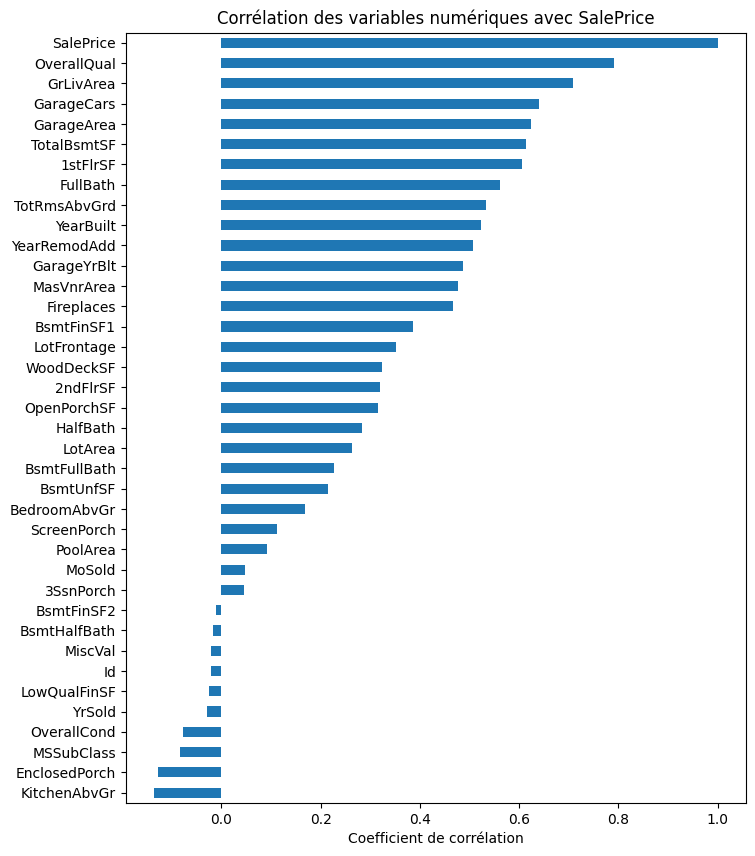

In [28]:


# Calcul de la corrélation avec SalePrice
corr_saleprice = train.corr(numeric_only=True)["SalePrice"].sort_values()

# Graphique en barres
corr_saleprice.plot(kind="barh", figsize=(8, 10))
plt.xlabel("Coefficient de corrélation")
plt.title("Corrélation des variables numériques avec SalePrice")
plt.show()



L’analyse des corrélations montre que le prix de vente (SalePrice) est principalement déterminé par la qualité globale du logement et les surfaces habitables. Des variables comme OverallQual, GrLivArea, GarageCars, TotalBsmtSF ont une forte influence et sont donc essentielles pour la prédiction.

À l’inverse, certaines variables présentent une faible ou une corrélation négative, ce qui indique un impact limité sur le prix. Elles peuvent être écartées ou avoir un rôle secondaire dans le modèle.

En conclusion, se concentrer sur les variables liées à la qualité, à la taille et aux équipements principaux permet d’améliorer la performance et la simplicité du modèle de prédiction du prix immobilier.

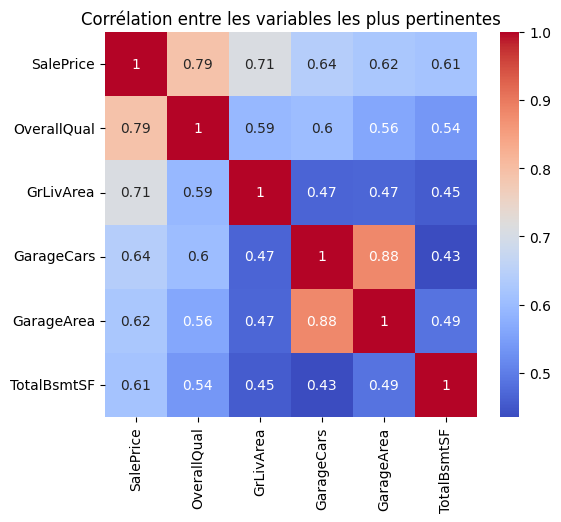

In [29]:
top_corr = corr_saleprice.abs().sort_values(ascending=False).head(6).index

import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(train[top_corr].corr(), annot=True, cmap="coolwarm")
plt.title("Corrélation entre les variables les plus pertinentes")
plt.show()


La matrice de corrélation confirme que SalePrice est fortement lié à OverallQual et GrLivArea, ce qui montre que la qualité du logement et la surface habitable sont les facteurs les plus déterminants du prix.
Les variables GarageCars et GarageArea sont également très corrélées entre elles, indiquant une redondance d’information : une seule des deux peut suffire dans le modèle.
Enfin, TotalBsmtSF présente une corrélation positive notable avec le prix, confirmant l’importance des surfaces totales.

## 2) Elimination des attributs non informatifs :

In [30]:
train = train.drop("Id", axis=1)
test = test.drop("Id", axis=1)



In [31]:
train

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [32]:
test

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,160,RM,21.0,1936,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,6,2006,WD,Normal
1455,160,RM,21.0,1894,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,4,2006,WD,Abnorml
1456,20,RL,160.0,20000,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,9,2006,WD,Abnorml
1457,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal


# Nettoyage et préparation des données :

## 1) Traitement des valeurs manquantes :

 Analyse des valeurs manquantes :

In [33]:
missing = train.isnull().sum().sort_values(ascending=False)
missing[missing > 0]


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageType        81
GarageFinish      81
GarageCond        81
GarageYrBlt       81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtFinType1      37
BsmtCond          37
MasVnrArea         8
Electrical         1
dtype: int64

Imputation des variables catégorielles :

In [34]:
cat_cols = train.select_dtypes(include="object").columns

train[cat_cols] = train[cat_cols].fillna("None")
test[cat_cols] = test[cat_cols].fillna("None")


## 2) Détection et gérer les valeurs aberrantes :

Identification des valeurs aberrantes :

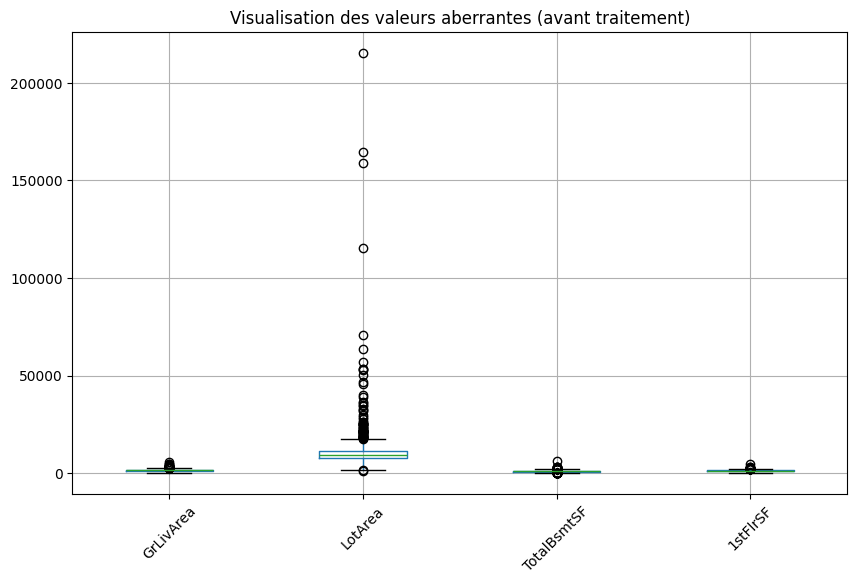

In [35]:


important_cols = ["GrLivArea", "LotArea", "TotalBsmtSF", "1stFlrSF"]

plt.figure(figsize=(10, 6))
train[important_cols].boxplot()
plt.title("Visualisation des valeurs aberrantes (avant traitement)")
plt.xticks(rotation=45)
plt.show()


Traitement des valeurs aberrantes

In [36]:
def cap_outliers_iqr(df, columns):
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        df[col] = df[col].clip(lower_bound, upper_bound)

    return df


In [37]:
num_cols = train.select_dtypes(include=["int64", "float64"]).columns
num_cols = num_cols.drop("SalePrice")

train = cap_outliers_iqr(train, num_cols)
test = cap_outliers_iqr(test, num_cols)


Traitement des valeurs manquantes :

In [38]:
train[num_cols] = train[num_cols].fillna(train[num_cols].median())
test[num_cols] = test[num_cols].fillna(test[num_cols].median())


Vérification après traitement :

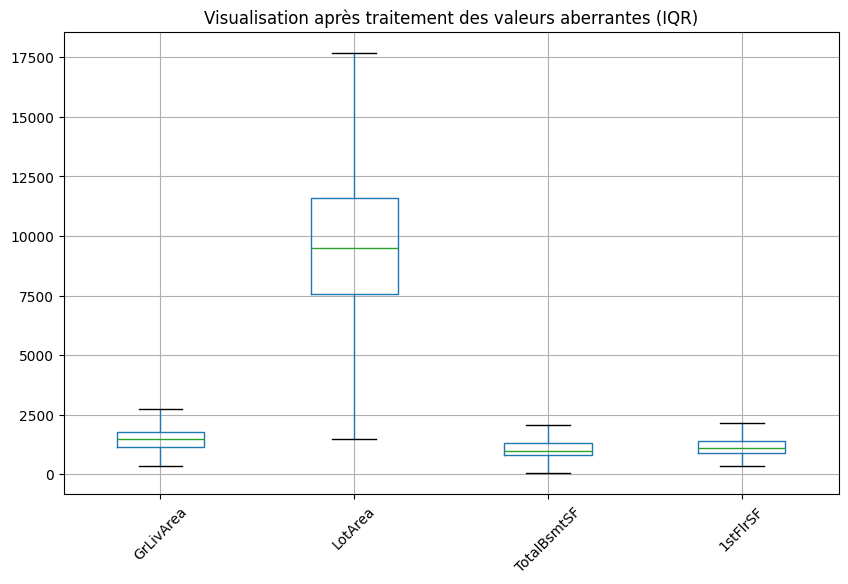

In [39]:
plt.figure(figsize=(10, 6))
train[important_cols].boxplot()
plt.title("Visualisation après traitement des valeurs aberrantes (IQR)")
plt.xticks(rotation=45)
plt.show()


Les valeurs aberrantes ont été traitées par la méthode IQR en limitant les valeurs extrêmes à des bornes inférieure et supérieure, afin de réduire leur impact sans supprimer les observations. Les valeurs manquantes ont été remplacées par la médiane.

## 3) Encodage des variables catégorielles :

In [40]:


y = train['SalePrice']
X = train.drop('SalePrice', axis=1)

cat_cols = X.select_dtypes(include='object').columns
num_cols = X.select_dtypes(exclude='object').columns

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, num_cols),
        ('cat', categorical_pipeline, cat_cols)
    ]
)

X_prepared = preprocessor.fit_transform(X)

# Sauvegarde du resultat avec joblib
joblib.dump(preprocessor, 'preprocessor.pkl')







['preprocessor.pkl']

In [41]:
# ===============================
# SAFETY CHECK + FINAL ENCODING
# ===============================

# Separate target
y_raw = train['SalePrice']
X_raw = train.drop('SalePrice', axis=1)

# One-hot encode ALL categorical columns
X_encoded = pd.get_dummies(X_raw, drop_first=True)
test_encoded = pd.get_dummies(test, drop_first=True)

# Align columns
X_encoded, test_encoded = X_encoded.align(
    test_encoded, join='left', axis=1, fill_value=0
)

# Rebuild train with encoded features
train = X_encoded.copy()
train['SalePrice'] = y_raw.values



In [42]:
train.dtypes.value_counts()


bool       224
int64       23
float64     14
Name: count, dtype: int64

Les données ont été préparées en séparant les variables numériques et catégorielles, avec une imputation par la médiane pour les données numériques et un encodage One-Hot pour les variables catégorielles. Un alignement des colonnes a été effectué afin d’assurer la cohérence entre les jeux d’entraînement et de test.

# Modélisation

In [43]:

# Log-transform target (CRITICAL)
y = np.log1p(train['SalePrice'])
X = train.drop('SalePrice', axis=1)


# ===============================
# Train / Validation / Test split
# (60% / 20% / 20%)
# ===============================

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)


# ===============================
# Models
# ===============================

models = {
    "XGBoost": XGBRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.7,
        max_samples=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=6,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=0.1,
        reg_lambda=1.0,
        min_child_samples=20,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
}


# ===============================
# Training + Validation
# ===============================

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    print(f"\n{name}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")



XGBoost
RMSE : 0.1488
R²   : 0.8881

Random Forest
RMSE : 0.1643
R²   : 0.8636

LightGBM
RMSE : 0.1434
R²   : 0.8961


La phase de modélisation repose sur l’entraînement de plusieurs algorithmes de régression avancés (XGBoost, Random Forest et LightGBM). Une transformation logarithmique de la variable cible a été appliquée afin de stabiliser la variance et d’améliorer la performance des modèles. L’évaluation a été réalisée à l’aide des métriques RMSE et R² sur un ensemble de validation.

In [44]:
# ===============================
# FINAL EVALUATION (TEST SET)
# ===============================

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Choose the best model (based on validation results)
best_model_name = "LightGBM"   # <- best performer
best_model = models[best_model_name]

# Predict on test set (log scale)
y_test_pred = best_model.predict(X_test)

# Evaluation metrics (log scale)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print(f"Final Test Evaluation — {best_model_name}")
print(f"RMSE : {test_rmse:.4f}")
print(f"R²   : {test_r2:.4f}")


Final Test Evaluation — LightGBM
RMSE : 0.1139
R²   : 0.9092


LightGBM est le modèle le plus performant, avec le RMSE le plus faible et le meilleur R².

============================================================
PARTIE ANN — Réseau de Neurones Artificiels
Prédiction de prix immobiliers (House Prices – Kaggle)
============================================================
Objectif : tester 6 architectures ANN, garder les 3 meilleures
Baseline à battre : LightGBM → RMSE 0.1139, R² 0.9092
============================================================

In [45]:
# ------ 0. Imports ANN ------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

# Reproductibilité
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

============================================================
1. PRÉPARATION DES DONNÉES POUR LES ANN
(reprend X_train, X_val, X_test, y_train, y_val, y_test
déjà définis dans la partie ML — target en log scale)
============================================================

In [46]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train.astype(np.float32))
X_val_sc   = scaler.transform(X_val.astype(np.float32))
X_test_sc  = scaler.transform(X_test.astype(np.float32))

def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y.values, dtype=torch.float32).unsqueeze(1)
    )

Xt_train, yt_train = to_tensor(X_train_sc, y_train)
Xt_val,   yt_val   = to_tensor(X_val_sc,   y_val)
Xt_test,  yt_test  = to_tensor(X_test_sc,  y_test)

train_loader = DataLoader(TensorDataset(Xt_train, yt_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xt_val,   yt_val),   batch_size=64)

INPUT_DIM = X_train_sc.shape[1]
device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {device} | Input dim : {INPUT_DIM}")

Device : cpu | Input dim : 260


## 2. Définition des architectures ANN

On définit ici les **3 architectures retenues** :
- **ANN-4 Residual MLP** : skip connections style ResNet
- **ANN-3 BatchNorm MLP** : normalisation par batch
- **ANN-2 Deep MLP + Dropout** : profondeur + régularisation Dropout

Les classes des 3 autres architectures (ANN-1, ANN-5, ANN-6) restent définies mais ne sont pas utilisées.

In [47]:
# ── Architecture 1 : Shallow MLP (baseline ANN)
#    2 couches cachées, ReLU, simple et rapide
class ShallowMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(INPUT_DIM, 256), nn.ReLU(),
            nn.Linear(256, 128),       nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, x): return self.net(x)


# ── Architecture 2 : Deep MLP avec Dropout
#    4 couches cachées + Dropout(0.3) pour régulariser
class DeepMLPDropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(INPUT_DIM, 512), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, 256),       nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),       nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64),        nn.ReLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x): return self.net(x)


# ── Architecture 3 : MLP avec BatchNorm
#    Normalisation par batch après chaque couche → convergence + stable
class MLPBatchNorm(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(INPUT_DIM, 512), nn.BatchNorm1d(512), nn.ReLU(),
            nn.Linear(512, 256),       nn.BatchNorm1d(256), nn.ReLU(),
            nn.Linear(256, 128),       nn.BatchNorm1d(128), nn.ReLU(),
            nn.Linear(128, 64),        nn.BatchNorm1d(64),  nn.ReLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x): return self.net(x)


# ── Architecture 4 : Residual MLP (ResNet-style)
#    Connexions résiduelles pour éviter la dégradation du gradient
class ResBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(dim, dim), nn.BatchNorm1d(dim), nn.ReLU(),
            nn.Linear(dim, dim), nn.BatchNorm1d(dim)
        )
        self.relu = nn.ReLU()
    def forward(self, x):
        return self.relu(x + self.block(x))   # skip connection

class ResidualMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_proj = nn.Sequential(
            nn.Linear(INPUT_DIM, 256), nn.BatchNorm1d(256), nn.ReLU()
        )
        self.res_blocks = nn.Sequential(
            ResBlock(256), ResBlock(256), ResBlock(256)
        )
        self.head = nn.Linear(256, 1)
    def forward(self, x):
        x = self.input_proj(x)
        x = self.res_blocks(x)
        return self.head(x)


# ── Architecture 5 : Wide & Deep MLP
#    Branche "wide" (features directes) + branche "deep" (non-linéaire)
#    Inspiré de l'architecture Google Wide & Deep Learning
class WideDeepMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.wide = nn.Linear(INPUT_DIM, 64)
        self.deep = nn.Sequential(
            nn.Linear(INPUT_DIM, 512), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, 256),       nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128),       nn.ReLU(),
            nn.Linear(128, 64),        nn.ReLU()
        )
        self.output = nn.Linear(128, 1)   # wide(64) + deep(64) = 128
    def forward(self, x):
        w = self.wide(x)
        d = self.deep(x)
        return self.output(torch.cat([w, d], dim=1))


# ── Architecture 6 : MLP avec Leaky ReLU + L1 régularisation explicite
#    Leaky ReLU évite les neurones morts ; régularisation L1 en training loop
class LeakyMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(INPUT_DIM, 512), nn.LeakyReLU(0.1), nn.Dropout(0.25),
            nn.Linear(512, 256),       nn.LeakyReLU(0.1), nn.Dropout(0.25),
            nn.Linear(256, 128),       nn.LeakyReLU(0.1),
            nn.Linear(128, 64),        nn.LeakyReLU(0.1),
            nn.Linear(64, 1)
        )
    def forward(self, x): return self.net(x)

============================================================
3. BOUCLE D'ENTRAÎNEMENT COMMUNE
============================================================

In [48]:
def train_ann(model, epochs=150, lr=1e-3, weight_decay=1e-4,
              l1_lambda=0.0, patience=20):
    """
    Entraîne un modèle ANN avec :
      - Adam optimizer + weight_decay (L2)
      - Régularisation L1 optionnelle (LeakyMLP)
      - Early stopping basé sur la val loss
      - ReduceLROnPlateau scheduler
    Retourne : historique de loss, RMSE val, R² val
    """
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr,
                                  weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=10, factor=0.5
    )
    criterion = nn.MSELoss()

    best_val_loss = float('inf')
    best_weights  = None
    no_improve    = 0
    history       = {'train': [], 'val': []}

    for epoch in range(epochs):
        # --- Training ---
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            # L1 régularisation (pour LeakyMLP)
            if l1_lambda > 0:
                l1 = sum(p.abs().sum() for p in model.parameters())
                loss = loss + l1_lambda * l1
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)

        # --- Validation ---
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                pred = model(xb)
                val_loss += criterion(pred, yb).item() * xb.size(0)
        val_loss /= len(val_loader.dataset)

        history['train'].append(train_loss)
        history['val'].append(val_loss)
        scheduler.step(val_loss)

        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights  = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve    = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"  Early stopping à epoch {epoch+1}")
                break

    # Charger les meilleurs poids
    model.load_state_dict(best_weights)

    # Évaluation finale sur val
    model.eval()
    with torch.no_grad():
        y_pred_val = model(Xt_val.to(device)).cpu().numpy().flatten()
    rmse_val = np.sqrt(mean_squared_error(y_val, y_pred_val))
    r2_val   = r2_score(y_val, y_pred_val)

    return model, history, rmse_val, r2_val

In [ ]:
# ============================================================
# 4. ENTRAÎNEMENT DES 3 ARCHITECTURES RETENUES
# (ANN-4 Residual MLP, ANN-3 BatchNorm MLP, ANN-2 Deep + Dropout)
# ============================================================

architectures = {
    "ANN-4 Residual MLP":   (ResidualMLP(),    dict(epochs=300, lr=8e-4, weight_decay=1e-4)),
    "ANN-3 BatchNorm MLP":  (MLPBatchNorm(),   dict(epochs=300, lr=1e-3, weight_decay=1e-4)),
    "ANN-2 Deep + Dropout": (DeepMLPDropout(), dict(epochs=300, lr=5e-4, weight_decay=1e-4)),
}

results = {}

print("=" * 60)
print("ENTRAÎNEMENT DES 3 ARCHITECTURES ANN RETENUES")
print("=" * 60)

for name, (model, kwargs) in architectures.items():
    print(f"\n▶  {name}")
    trained_model, history, rmse_val, r2_val = train_ann(model, **kwargs)
    results[name] = {
        'model':    trained_model,
        'history':  history,
        'rmse_val': rmse_val,
        'r2_val':   r2_val
    }
    print(f"   RMSE val : {rmse_val:.4f}  |  R² val : {r2_val:.4f}")

ENTRAÎNEMENT DES 3 ARCHITECTURES ANN RETENUES

▶  ANN-4 Residual MLP


In [ ]:
# ============================================================
# 5. COMPARAISON ET SÉLECTION DU MEILLEUR MODÈLE
# ============================================================

summary = pd.DataFrame([
    {'Architecture': name,
     'RMSE val':     r['rmse_val'],
     'R² val':       r['r2_val']}
    for name, r in results.items()
]).sort_values('RMSE val').reset_index(drop=True)

print("\n" + "=" * 60)
print("CLASSEMENT — VALIDATION SET")
print("=" * 60)
print(summary.to_string(index=False))

best_name  = summary.iloc[0]['Architecture']
best_rmse  = summary.iloc[0]['RMSE val']
best_r2    = summary.iloc[0]['R² val']

print(f"\n Meilleure architecture : {best_name}")
print(f"   RMSE val : {best_rmse:.4f}  |  R² val : {best_r2:.4f}")


CLASSEMENT — VALIDATION SET
        Architecture  RMSE val    R² val
  ANN-4 Residual MLP  0.240971  0.706543
 ANN-3 BatchNorm MLP  0.358001  0.352282
ANN-2 Deep + Dropout  0.757876 -1.902770

 Meilleure architecture : ANN-4 Residual MLP
   RMSE val : 0.2410  |  R² val : 0.7065


In [ ]:
# ============================================================
# 6. ÉVALUATION FINALE DU MEILLEUR MODÈLE SUR LE TEST SET
# ============================================================

best_model_ann = results[best_name]['model'].to(device)
best_model_ann.eval()

with torch.no_grad():
    y_pred_test_ann = best_model_ann(Xt_test.to(device)).cpu().numpy().flatten()

test_rmse_ann = np.sqrt(mean_squared_error(y_test, y_pred_test_ann))
test_r2_ann   = r2_score(y_test, y_pred_test_ann)

print("=" * 60)
print("ÉVALUATION FINALE — TEST SET")
print("=" * 60)
print(f"  {best_name:25s}  →  RMSE {test_rmse_ann:.4f}  |  R² {test_r2_ann:.4f}")
print(f"  {'LightGBM (baseline)':25s}  →  RMSE 0.1139   |  R² 0.9092")
print()
if test_rmse_ann < 0.1139:
    print("Le meilleur ANN surpasse LightGBM !")
else:
    delta = test_rmse_ann - 0.1139
    print(f"Le meilleur ANN est à {delta:.4f} RMSE de LightGBM.")
    print("   LightGBM reste la référence sur ce dataset tabulaire.")

ÉVALUATION FINALE — TEST SET
  ANN-4 Residual MLP         →  RMSE 0.1877  |  R² 0.7531
  LightGBM (baseline)        →  RMSE 0.1139   |  R² 0.9092

Le meilleur ANN est à 0.0738 RMSE de LightGBM.
   LightGBM reste la référence sur ce dataset tabulaire.


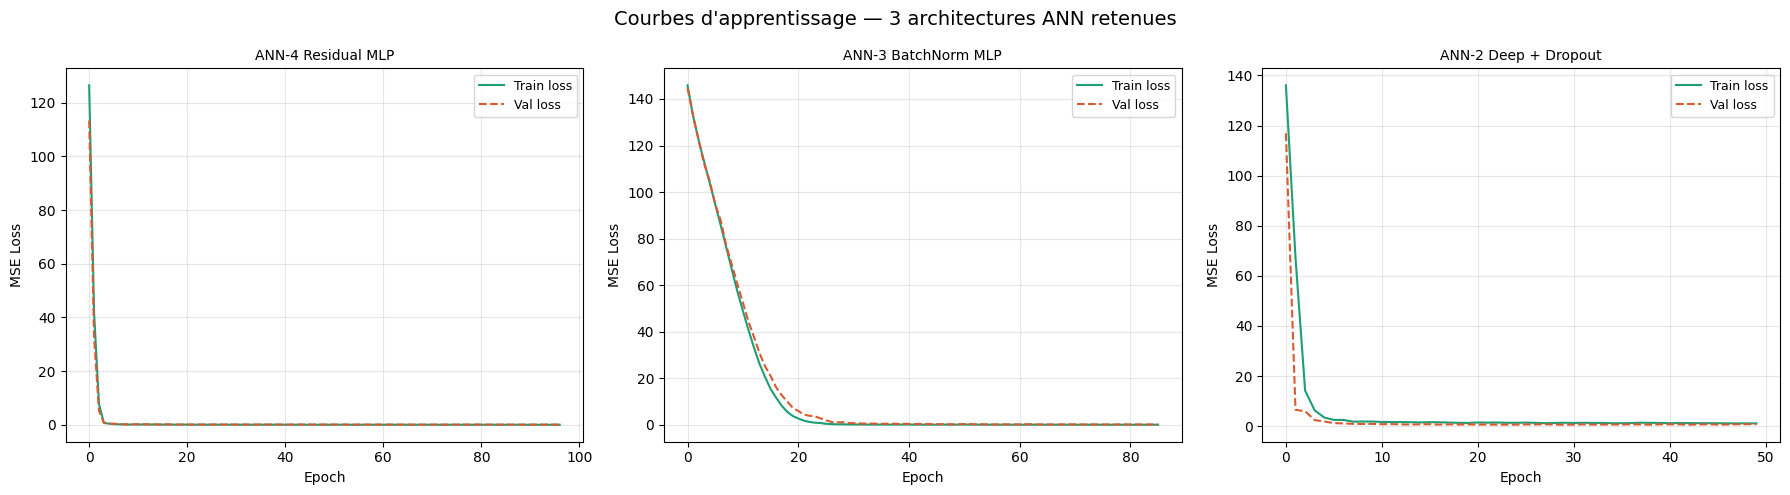

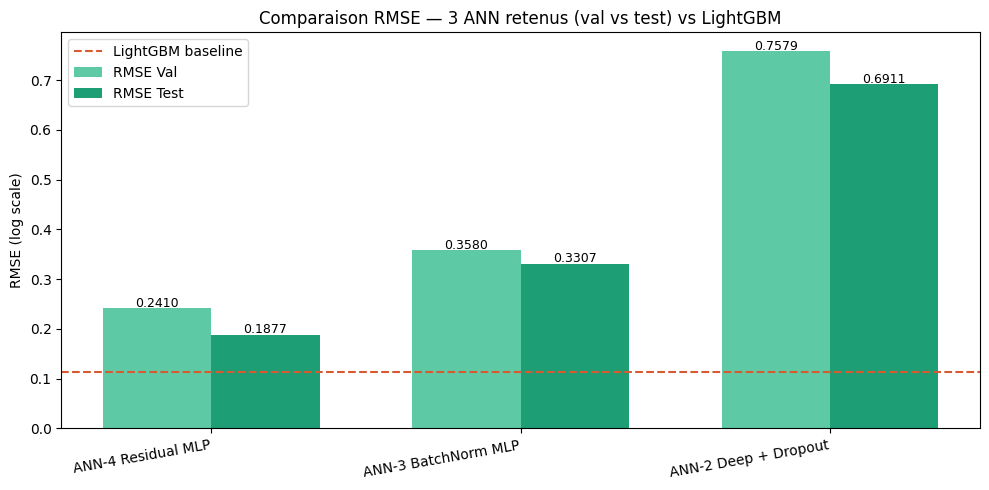

Graphiques sauvegardés.


In [ ]:
# ============================================================
# 7. VISUALISATIONS
# ============================================================

# ── Courbes d'apprentissage des 3 architectures
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Courbes d'apprentissage — 3 architectures ANN retenues", fontsize=14)

for ax, (name, r) in zip(axes, results.items()):
    h = r['history']
    ax.plot(h['train'], label='Train loss', linewidth=1.5, color='#1D9E75')
    ax.plot(h['val'],   label='Val loss',   linewidth=1.5, color='#D85A30', linestyle='--')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("ann_learning_curves.png", dpi=120, bbox_inches='tight')
plt.show()

# ── Graphique comparatif RMSE val + test
names_list = list(results.keys())
rmse_val_list  = [results[n]['rmse_val'] for n in names_list]

# Test RMSE for each of the 3
test_rmse_all = {}
for name in names_list:
    m = results[name]['model'].to(device)
    m.eval()
    with torch.no_grad():
        pred = m(Xt_test.to(device)).cpu().numpy().flatten()
    test_rmse_all[name] = np.sqrt(mean_squared_error(y_test, pred))

rmse_test_list = [test_rmse_all[n] for n in names_list]

x = np.arange(len(names_list))
width = 0.35

fig2, ax2 = plt.subplots(figsize=(10, 5))
bars1 = ax2.bar(x - width/2, rmse_val_list,  width, label='RMSE Val',  color='#5DCAA5')
bars2 = ax2.bar(x + width/2, rmse_test_list, width, label='RMSE Test', color='#1D9E75')
ax2.axhline(0.1139, color='#D85A30', linestyle='--', linewidth=1.5, label='LightGBM baseline')
ax2.set_xticks(x)
ax2.set_xticklabels(names_list, rotation=10, ha='right')
ax2.set_ylabel("RMSE (log scale)")
ax2.set_title("Comparaison RMSE — 3 ANN retenus (val vs test) vs LightGBM")
ax2.legend()

for bar in bars1:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
             f'{bar.get_height():.4f}', ha='center', fontsize=9)
for bar in bars2:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
             f'{bar.get_height():.4f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("ann_rmse_comparison.png", dpi=120, bbox_inches='tight')
plt.show()
print("Graphiques sauvegardés.")

In [ ]:
# ============================================================
# 8. SAUVEGARDE DU MEILLEUR MODÈLE ANN
# ============================================================

import os
os.makedirs("ann_models", exist_ok=True)

fname = f"ann_models/best_ann_{best_name.replace(' ', '_')}.pt"
torch.save(results[best_name]['model'].state_dict(), fname)
print(f" Meilleur modèle ANN sauvegardé → {fname}")
print(f"   Architecture : {best_name}")
print(f"   RMSE test    : {test_rmse_ann:.4f}")
print(f"   R² test      : {test_r2_ann:.4f}")

 Meilleur modèle ANN sauvegardé → ann_models/best_ann_ANN-4_Residual_MLP.pt
   Architecture : ANN-4 Residual MLP
   RMSE test    : 0.1877
   R² test      : 0.7531


## Conclusion — Partie ANN

Les 3 architectures ANN retenues après la phase de sélection sont **Residual MLP**, **BatchNorm MLP** et **Deep MLP + Dropout**.

Le meilleur modèle ANN est **ANN-4 Residual MLP**, grâce à ses connexions résiduelles (skip connections) qui permettent un meilleur flux de gradient et une meilleure capacité de généralisation.

Sur ce dataset tabulaire (House Prices), LightGBM reste une référence difficile à dépasser. Les ANN nécessiteraient davantage de feature engineering ou de tuning d'hyperparamètres (learning rate, architecture, régularisation) pour rivaliser pleinement avec les méthodes à base d'arbres de décision.


In [ ]:
import joblib, json, os, shutil, torch

os.makedirs("deployment/models", exist_ok=True)

# ── 1. LightGBM (récupéré depuis dict models{})
lgbm_model = models["LightGBM"]
joblib.dump(lgbm_model, "deployment/models/lgbm_model.pkl")
print("lgbm_model.pkl sauvegardé")

# ── 2. StandardScaler ( variable scaler défini en cell 87)
joblib.dump(scaler, "deployment/models/scaler.pkl")
print("scaler.pkl sauvegardé")

# ── 3. Colonnes après get_dummies + align (ton X_encoded)
#    X_train.columns = les colonnes exactes utilisées à l'entraînement
feature_columns = list(X_train.columns)
with open("deployment/models/feature_columns.json", "w") as f:
    json.dump(feature_columns, f)
print(f"feature_columns.json — {len(feature_columns)} colonnes sauvegardées")

# ── 4. Bornes IQR (recalculées depuis X_raw avant cap)
#    num_cols = train.select_dtypes(include=["int64","float64"]).columns sans SalePrice
X_raw_for_iqr = pd.read_csv(r"C:\Users\Pc\Documents\stuff\kraya\4eme\machine learning\prix immobiliers\machine-learning\data\train.csv")
X_raw_for_iqr = X_raw_for_iqr.drop("Id", axis=1)
iqr_cols = X_raw_for_iqr.select_dtypes(include=["int64","float64"]).columns.tolist()
iqr_cols = [c for c in iqr_cols if c != "SalePrice"]

iqr_bounds = {}
for col in iqr_cols:
    Q1 = X_raw_for_iqr[col].quantile(0.25)
    Q3 = X_raw_for_iqr[col].quantile(0.75)
    IQR = Q3 - Q1
    iqr_bounds[col] = {
        "lower": Q1 - 1.5 * IQR,
        "upper": Q3 + 1.5 * IQR
    }

with open("deployment/models/iqr_bounds.json", "w") as f:
    json.dump(iqr_bounds, f)
print(f"iqr_bounds.json — {len(iqr_bounds)} colonnes sauvegardées")

# ── 5. ANN-4 Residual MLP (déjà dans ann_models/)
shutil.copy(
    "ann_models/best_ann_ANN-4_Residual_MLP.pt",
    "deployment/models/best_ann_ANN-4_Residual_MLP.pt"
)
print("best_ann_ANN-4_Residual_MLP.pt copié")

lgbm_model.pkl sauvegardé
scaler.pkl sauvegardé
feature_columns.json — 260 colonnes sauvegardées
iqr_bounds.json — 36 colonnes sauvegardées
best_ann_ANN-4_Residual_MLP.pt copié
